# Лабораторная работа 4

Tensorflow 2.x

1) Подготовка данных

2) Использование Keras Model API

3) Использование Keras Sequential + Functional API

https://www.tensorflow.org/tutorials

Для выполнения лабораторной работы необходимо установить tensorflow версии 2.0 или выше .

Рекомендуется использовать возможности Colab'а по обучению моделей на GPU.



In [1]:
import os
import tensorflow as tf
import numpy as np
import math
import timeit
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
# Скрытие служебных предупреждений TensorFlow
tf.get_logger().setLevel('ERROR')

# Видеокарта, если она есть, иначе процессор
USE_GPU = len(tf.config.list_physical_devices('GPU')) > 0
device = '/device:GPU:0' if USE_GPU else '/cpu:0'

# Как часто (в итерациях) цикл обучения печатает точность на валидации
print_every = 100

# Инициализаторы весов берутся из tf.keras, если в tf их нет
if not hasattr(tf, 'initializers') or not hasattr(tf.initializers, 'VarianceScaling'):
    tf.initializers = tf.keras.initializers

In [3]:
import pickle
import tarfile

CIFAR10_DIR = 'cifar-10-batches-py'

if not os.path.isdir(CIFAR10_DIR):
    with tarfile.open(os.path.join('..', 'cifar-10-python.tar.gz')) as archive:
        if hasattr(tarfile, 'data_filter'):
            archive.extractall('.', filter='data')
        else:
            archive.extractall('.')


# Чтение одного файла CIFAR-10: картинки (N, 32, 32, 3) и метки (N,)
def read_cifar10_batch(path):
    with open(path, 'rb') as f:
        batch = pickle.load(f, encoding='latin1')
    images = batch['data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    labels = np.array(batch['labels'])
    return images, labels


# Загрузка CIFAR-10 из распакованной папки в виде ((X_train, y_train), (X_test, y_test)):
# 50000 обучающих и 10000 тестовых картинок
def load_cifar10_local(root=CIFAR10_DIR):
    parts = [read_cifar10_batch(os.path.join(root, 'data_batch_%d' % i)) for i in range(1, 6)]
    X_train = np.concatenate([p[0] for p in parts])
    y_train = np.concatenate([p[1] for p in parts])
    X_test, y_test = read_cifar10_batch(os.path.join(root, 'test_batch'))
    return (X_train, y_train), (X_test, y_test)

# Подготовка данных
Загрузите набор данных из предыдущей лабораторной работы.

In [4]:
# Загрузка CIFAR-10, разбиение на обучающую, валидационную и тестовую выборки и нормировка
def load_cifar10(num_training=49000, num_validation=1000, num_test=10000):
    # Load the raw CIFAR-10 dataset and use appropriate data types and shapes
    cifar10 = load_cifar10_local()
    (X_train, y_train), (X_test, y_test) = cifar10
    X_train = np.asarray(X_train, dtype=np.float32)
    y_train = np.asarray(y_train, dtype=np.int32).flatten()
    X_test = np.asarray(X_test, dtype=np.float32)
    y_test = np.asarray(y_test, dtype=np.int32).flatten()

    # Subsample the data
    mask = range(num_training, num_training + num_validation)
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = range(num_training)
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = range(num_test)
    X_test = X_test[mask]
    y_test = y_test[mask]

    # Normalize the data: subtract the mean pixel and divide by std
    mean_pixel = X_train.mean(axis=(0, 1, 2), keepdims=True)
    std_pixel = X_train.std(axis=(0, 1, 2), keepdims=True)
    X_train = (X_train - mean_pixel) / std_pixel
    X_val = (X_val - mean_pixel) / std_pixel
    X_test = (X_test - mean_pixel) / std_pixel

    return X_train, y_train, X_val, y_val, X_test, y_test

# Invoke the above function to get our data.
NHW = (0, 1, 2)
X_train, y_train, X_val, y_val, X_test, y_test = load_cifar10()
print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape, y_train.dtype)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 32, 32, 3)
Train labels shape:  (49000,) int32
Validation data shape:  (1000, 32, 32, 3)
Validation labels shape:  (1000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


In [5]:
# Перебор данных X и меток y батчами по batch_size; при shuffle=True порядок перемешивается каждую эпоху
class Dataset(object):
    def __init__(self, X, y, batch_size, shuffle=False):
        assert X.shape[0] == y.shape[0], 'Got different numbers of data and labels'
        self.X, self.y = X, y
        self.batch_size, self.shuffle = batch_size, shuffle

    def __iter__(self):
        N, B = self.X.shape[0], self.batch_size
        idxs = np.arange(N)
        if self.shuffle:
            np.random.shuffle(idxs)
        return iter((self.X[idxs[i:i+B]], self.y[idxs[i:i+B]]) for i in range(0, N, B))


train_dset = Dataset(X_train, y_train, batch_size=64, shuffle=True)
val_dset = Dataset(X_val, y_val, batch_size=64, shuffle=False)
test_dset = Dataset(X_test, y_test, batch_size=64)

In [6]:
# We can iterate through a dataset like this:
for t, (x, y) in enumerate(train_dset):
    print(t, x.shape, y.shape)
    if t > 5: break

0 (64, 32, 32, 3) (64,)
1 (64, 32, 32, 3) (64,)
2 (64, 32, 32, 3) (64,)
3 (64, 32, 32, 3) (64,)
4 (64, 32, 32, 3) (64,)
5 (64, 32, 32, 3) (64,)
6 (64, 32, 32, 3) (64,)


#  Keras Model Subclassing API


Для реализации собственной модели с помощью Keras Model Subclassing API необходимо выполнить следующие шаги:

1) Определить новый класс, который является наследником tf.keras.Model.

2) В методе __init__() определить все необходимые слои из модуля tf.keras.layer

3) Реализовать прямой проход в методе call() на основе слоев, объявленных в __init__()

Ниже приведен пример использования keras API для определения двухслойной полносвязной сети.

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras

In [7]:
class TwoLayerFC(tf.keras.Model):
    def __init__(self, hidden_size, num_classes):
        super(TwoLayerFC, self).__init__()
        initializer = tf.initializers.VarianceScaling(scale=2.0)
        self.fc1 = tf.keras.layers.Dense(hidden_size, activation='relu',
                                   kernel_initializer=initializer)
        self.fc2 = tf.keras.layers.Dense(num_classes, activation='softmax',
                                   kernel_initializer=initializer)
        self.flatten = tf.keras.layers.Flatten()

    def call(self, x, training=False):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.fc2(x)
        return x


# Проверка: сеть TwoLayerFC возвращает оценки формы (64, 10)
def test_TwoLayerFC():
    input_size, hidden_size, num_classes = 50, 42, 10
    x = tf.zeros((64, input_size))
    model = TwoLayerFC(hidden_size, num_classes)
    with tf.device(device):
        scores = model(x)
        print(scores.shape)

test_TwoLayerFC()

(64, 10)


Реализуйте трехслойную CNN для вашей задачи классификации.

Архитектура сети:
    
1. Сверточный слой (5 x 5 kernels, zero-padding = 'same')
2. Функция активации ReLU
3. Сверточный слой (3 x 3 kernels, zero-padding = 'same')
4. Функция активации ReLU
5. Полносвязный слой
6. Функция активации Softmax

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Conv2D

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Dense

In [8]:
class ThreeLayerConvNet(tf.keras.Model):
    def __init__(self, channel_1, channel_2, num_classes):
        super(ThreeLayerConvNet, self).__init__()
        ########################################################################
        # TODO: Implement the __init__ method for a three-layer ConvNet. You   #
        # should instantiate layer objects to be used in the forward pass.     #
        ########################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        # Слои сети: свёртка 5x5, свёртка 3x3 (обе с ReLU и сохранением размера), полносвязный выход
        initializer = tf.initializers.VarianceScaling(scale=2.0)
        self.conv1 = tf.keras.layers.Conv2D(channel_1, 5, padding='same', activation='relu',
                                            kernel_initializer=initializer)
        self.conv2 = tf.keras.layers.Conv2D(channel_2, 3, padding='same', activation='relu',
                                            kernel_initializer=initializer)
        self.flatten = tf.keras.layers.Flatten()
        self.fc = tf.keras.layers.Dense(num_classes, activation='softmax',
                                        kernel_initializer=initializer)

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ########################################################################
        #                           END OF YOUR CODE                           #
        ########################################################################

    def call(self, x, training=False):
        scores = None
        ########################################################################
        # TODO: Implement the forward pass for a three-layer ConvNet. You      #
        # should use the layer objects defined in the __init__ method.         #
        ########################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        x = self.conv1(x)
        x = self.conv2(x)
        x = self.flatten(x)
        scores = self.fc(x)

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ########################################################################
        #                           END OF YOUR CODE                           #
        ########################################################################
        return scores

In [9]:
def test_ThreeLayerConvNet():
    channel_1, channel_2, num_classes = 12, 8, 10
    model = ThreeLayerConvNet(channel_1, channel_2, num_classes)
    with tf.device(device):
        x = tf.zeros((64, 3, 32, 32))
        scores = model(x)
        print(scores.shape)

test_ThreeLayerConvNet()

(64, 10)


Пример реализации процесса обучения:

In [10]:
# Цикл обучения модели на CIFAR-10 с проверкой точности на валидации каждые print_every итераций
# model_init_fn и optimizer_init_fn — функции без параметров, которые создают модель и оптимизатор
def train_part34(model_init_fn, optimizer_init_fn, num_epochs=1, is_training=False):
    with tf.device(device):


        loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()

        model = model_init_fn()
        optimizer = optimizer_init_fn()

        train_loss = tf.keras.metrics.Mean(name='train_loss')
        train_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name='train_accuracy')

        val_loss = tf.keras.metrics.Mean(name='val_loss')
        val_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name='val_accuracy')

        t = 0
        for epoch in range(num_epochs):

            # Reset the metrics - https://www.tensorflow.org/alpha/guide/migration_guide#new-style_metrics
            train_loss.reset_state()
            train_accuracy.reset_state()

            for x_np, y_np in train_dset:
                with tf.GradientTape() as tape:

                    # Use the model function to build the forward pass.
                    scores = model(x_np, training=is_training)
                    loss = loss_fn(y_np, scores)

                    gradients = tape.gradient(loss, model.trainable_variables)
                    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

                    # Update the metrics
                    train_loss.update_state(loss)
                    train_accuracy.update_state(y_np, scores)

                    if t % print_every == 0:
                        val_loss.reset_state()
                        val_accuracy.reset_state()
                        for test_x, test_y in val_dset:
                            # During validation at end of epoch, training set to False
                            prediction = model(test_x, training=False)
                            t_loss = loss_fn(test_y, prediction)

                            val_loss.update_state(t_loss)
                            val_accuracy.update_state(test_y, prediction)

                        template = 'Iteration {}, Epoch {}, Loss: {}, Accuracy: {}, Val Loss: {}, Val Accuracy: {}'
                        print (template.format(t, epoch+1,
                                             train_loss.result(),
                                             train_accuracy.result()*100,
                                             val_loss.result(),
                                             val_accuracy.result()*100))
                    t += 1

In [11]:
hidden_size, num_classes = 4000, 10
learning_rate = 1e-2

def model_init_fn():
    return TwoLayerFC(hidden_size, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 3.3210372924804688, Accuracy: 7.8125, Val Loss: 3.094295024871826, Val Accuracy: 14.100000381469727
Iteration 100, Epoch 1, Loss: 2.189920425415039, Accuracy: 29.223390579223633, Val Loss: 1.9222663640975952, Val Accuracy: 35.0
Iteration 200, Epoch 1, Loss: 2.067521810531616, Accuracy: 32.14396667480469, Val Loss: 1.9288588762283325, Val Accuracy: 37.599998474121094
Iteration 300, Epoch 1, Loss: 1.9918354749679565, Accuracy: 33.964908599853516, Val Loss: 1.7911148071289062, Val Accuracy: 42.39999771118164
Iteration 400, Epoch 1, Loss: 1.9311649799346924, Accuracy: 35.4543342590332, Val Loss: 1.7281959056854248, Val Accuracy: 43.5
Iteration 500, Epoch 1, Loss: 1.8962448835372925, Accuracy: 36.38972091674805, Val Loss: 1.7203774452209473, Val Accuracy: 42.599998474121094
Iteration 600, Epoch 1, Loss: 1.8661404848098755, Accuracy: 37.33361053466797, Val Loss: 1.7109019756317139, Val Accuracy: 40.900001525878906
Iteration 700, Epoch 1, Loss: 1.8358200788497925, 

Обучите трехслойную CNN. В tf.keras.optimizers.SGD укажите Nesterov momentum = 0.9 .

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/optimizers/SGD

Значение accuracy на валидационной выборке после 1 эпохи обучения должно быть > 50% .

In [12]:
learning_rate = 3e-3
channel_1, channel_2, num_classes = 32, 16, 10

def model_init_fn():
    model = None
    ############################################################################
    # TODO: Complete the implementation of model_fn.                           #
    ############################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

    model = ThreeLayerConvNet(channel_1, channel_2, num_classes)

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ############################################################################
    #                           END OF YOUR CODE                               #
    ############################################################################
    return model

def optimizer_init_fn():
    optimizer = None
    ############################################################################
    # TODO: Complete the implementation of model_fn.                           #
    ############################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

    # SGD с моментом Нестерова 0.9
    optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9, nesterov=True)

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ############################################################################
    #                           END OF YOUR CODE                               #
    ############################################################################
    return optimizer

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 2.676212787628174, Accuracy: 7.8125, Val Loss: 4.538788318634033, Val Accuracy: 12.100000381469727
Iteration 100, Epoch 1, Loss: 2.0153512954711914, Accuracy: 31.033414840698242, Val Loss: 1.6844667196273804, Val Accuracy: 42.099998474121094
Iteration 200, Epoch 1, Loss: 1.8038296699523926, Accuracy: 37.11909103393555, Val Loss: 1.514070749282837, Val Accuracy: 48.89999771118164
Iteration 300, Epoch 1, Loss: 1.710827350616455, Accuracy: 39.991695404052734, Val Loss: 1.425079107284546, Val Accuracy: 51.20000076293945
Iteration 400, Epoch 1, Loss: 1.640002965927124, Accuracy: 42.269325256347656, Val Loss: 1.3390731811523438, Val Accuracy: 53.29999923706055
Iteration 500, Epoch 1, Loss: 1.5824180841445923, Accuracy: 44.19910430908203, Val Loss: 1.3060996532440186, Val Accuracy: 55.400001525878906
Iteration 600, Epoch 1, Loss: 1.538380742073059, Accuracy: 45.824668884277344, Val Loss: 1.3248543739318848, Val Accuracy: 54.20000076293945
Iteration 700, Epoch 1, Lo

# Использование Keras Sequential API для реализации последовательных моделей.

Пример для полносвязной сети:

In [13]:
learning_rate = 1e-2

def model_init_fn():
    input_shape = (32, 32, 3)
    hidden_layer_size, num_classes = 4000, 10
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    layers = [
        tf.keras.Input(shape=input_shape),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hidden_layer_size, activation='relu',
                              kernel_initializer=initializer),
        tf.keras.layers.Dense(num_classes, activation='softmax',
                              kernel_initializer=initializer),
    ]
    model = tf.keras.Sequential(layers)
    return model

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 2.9098165035247803, Accuracy: 14.0625, Val Loss: 2.7969038486480713, Val Accuracy: 17.200000762939453
Iteration 100, Epoch 1, Loss: 2.197600841522217, Accuracy: 28.7592830657959, Val Loss: 2.019400119781494, Val Accuracy: 35.20000076293945
Iteration 200, Epoch 1, Loss: 2.0890660285949707, Accuracy: 31.37437629699707, Val Loss: 1.9295728206634521, Val Accuracy: 35.29999923706055
Iteration 300, Epoch 1, Loss: 1.9995753765106201, Accuracy: 33.684593200683594, Val Loss: 1.8491874933242798, Val Accuracy: 40.5
Iteration 400, Epoch 1, Loss: 1.945887565612793, Accuracy: 35.37250900268555, Val Loss: 1.8445252180099487, Val Accuracy: 39.20000076293945
Iteration 500, Epoch 1, Loss: 1.905996561050415, Accuracy: 36.54254150390625, Val Loss: 1.683891773223877, Val Accuracy: 43.39999771118164
Iteration 600, Epoch 1, Loss: 1.8675144910812378, Accuracy: 37.55979537963867, Val Loss: 1.6712702512741089, Val Accuracy: 44.70000076293945
Iteration 700, Epoch 1, Loss: 1.8359931707

Альтернативный менее гибкий способ обучения:

In [14]:
model = model_init_fn()
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=learning_rate),
              loss='sparse_categorical_crossentropy',
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])
model.fit(X_train, y_train, batch_size=64, epochs=1, validation_data=(X_val, y_val))
model.evaluate(X_test, y_test)

766/766 ━━━━━━━━━━━━━━━━━━━━ 36s 47ms/step - loss: 1.8163 - sparse_categorical_accuracy: 0.3897 - val_loss: 1.6939 - val_sparse_categorical_accuracy: 0.4190
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 1.7050 - sparse_categorical_accuracy: 0.4174


[1.7050055265426636, 0.4174000024795532]

Перепишите реализацию трехслойной CNN с помощью tf.keras.Sequential API . Обучите модель двумя способами.

In [15]:
def model_init_fn():
    model = None
    ############################################################################
    # TODO: Construct a three-layer ConvNet using tf.keras.Sequential.         #
    ############################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

    # Та же трёхслойная сеть, собранная как последовательность слоёв
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(32, 32, 3)),
        tf.keras.layers.Conv2D(channel_1, 5, padding='same', activation='relu',
                               kernel_initializer=initializer),
        tf.keras.layers.Conv2D(channel_2, 3, padding='same', activation='relu',
                               kernel_initializer=initializer),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(num_classes, activation='softmax',
                              kernel_initializer=initializer),
    ])

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ############################################################################
    #                            END OF YOUR CODE                              #
    ############################################################################
    return model

learning_rate = 5e-4
def optimizer_init_fn():
    optimizer = None
    ############################################################################
    # TODO: Complete the implementation of model_fn.                           #
    ############################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

    # SGD с моментом Нестерова
    optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9, nesterov=True)

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ############################################################################
    #                           END OF YOUR CODE                               #
    ############################################################################
    return optimizer

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 3.8026819229125977, Accuracy: 9.375, Val Loss: 3.2250282764434814, Val Accuracy: 9.399999618530273
Iteration 100, Epoch 1, Loss: 2.082101583480835, Accuracy: 28.27970314025879, Val Loss: 1.7836278676986694, Val Accuracy: 38.10000228881836
Iteration 200, Epoch 1, Loss: 1.9107930660247803, Accuracy: 33.35665512084961, Val Loss: 1.6857211589813232, Val Accuracy: 42.599998474121094
Iteration 300, Epoch 1, Loss: 1.8190966844558716, Accuracy: 36.29568099975586, Val Loss: 1.577399492263794, Val Accuracy: 46.900001525878906
Iteration 400, Epoch 1, Loss: 1.7530988454818726, Accuracy: 38.516990661621094, Val Loss: 1.5282964706420898, Val Accuracy: 47.79999923706055
Iteration 500, Epoch 1, Loss: 1.706442952156067, Accuracy: 39.92639923095703, Val Loss: 1.484114646911621, Val Accuracy: 48.5
Iteration 600, Epoch 1, Loss: 1.6689528226852417, Accuracy: 41.18656539916992, Val Loss: 1.445345163345337, Val Accuracy: 49.70000076293945
Iteration 700, Epoch 1, Loss: 1.6345775127

In [16]:
model = model_init_fn()
model.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])
model.fit(X_train, y_train, batch_size=64, epochs=1, validation_data=(X_val, y_val))
model.evaluate(X_test, y_test)

766/766 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - loss: 1.6138 - sparse_categorical_accuracy: 0.4318 - val_loss: 1.4015 - val_sparse_categorical_accuracy: 0.4980
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.4253 - sparse_categorical_accuracy: 0.4934


[1.4253441095352173, 0.4934000074863434]

# Использование Keras Functional API

Для реализации более сложных архитектур сети с несколькими входами/выходами, повторным использованием слоев, "остаточными" связями (residual connections) необходимо явно указать входные и выходные тензоры.

Ниже представлен пример для полносвязной сети.

In [17]:
def two_layer_fc_functional(input_shape, hidden_size, num_classes):
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    inputs = tf.keras.Input(shape=input_shape)
    flattened_inputs = tf.keras.layers.Flatten()(inputs)
    fc1_output = tf.keras.layers.Dense(hidden_size, activation='relu',
                                 kernel_initializer=initializer)(flattened_inputs)
    scores = tf.keras.layers.Dense(num_classes, activation='softmax',
                             kernel_initializer=initializer)(fc1_output)

    # Instantiate the model given inputs and outputs.
    model = tf.keras.Model(inputs=inputs, outputs=scores)
    return model

# Проверка: сеть из two_layer_fc_functional возвращает оценки формы (64, 10)
def test_two_layer_fc_functional():
    input_size, hidden_size, num_classes = 50, 42, 10
    input_shape = (50,)

    x = tf.zeros((64, input_size))
    model = two_layer_fc_functional(input_shape, hidden_size, num_classes)

    with tf.device(device):
        scores = model(x)
        print(scores.shape)

test_two_layer_fc_functional()

(64, 10)


In [18]:
input_shape = (32, 32, 3)
hidden_size, num_classes = 4000, 10
learning_rate = 1e-2

def model_init_fn():
    return two_layer_fc_functional(input_shape, hidden_size, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 3.875237464904785, Accuracy: 6.25, Val Loss: 2.925281524658203, Val Accuracy: 16.30000114440918
Iteration 100, Epoch 1, Loss: 2.191169500350952, Accuracy: 28.63551902770996, Val Loss: 1.9785150289535522, Val Accuracy: 33.89999771118164
Iteration 200, Epoch 1, Loss: 2.0611162185668945, Accuracy: 32.462684631347656, Val Loss: 1.938297986984253, Val Accuracy: 35.79999923706055
Iteration 300, Epoch 1, Loss: 1.9809014797210693, Accuracy: 34.50477600097656, Val Loss: 1.7869373559951782, Val Accuracy: 40.29999923706055
Iteration 400, Epoch 1, Loss: 1.9283370971679688, Accuracy: 36.093360900878906, Val Loss: 1.6866989135742188, Val Accuracy: 43.79999923706055
Iteration 500, Epoch 1, Loss: 1.890838861465454, Accuracy: 36.969810485839844, Val Loss: 1.626183032989502, Val Accuracy: 44.80000305175781
Iteration 600, Epoch 1, Loss: 1.8609038591384888, Accuracy: 37.856178283691406, Val Loss: 1.751868486404419, Val Accuracy: 40.099998474121094
Iteration 700, Epoch 1, Loss: 

Поэкспериментируйте с архитектурой сверточной сети. Для вашего набора данных вам необходимо получить как минимум 70% accuracy на валидационной выборке за 10 эпох обучения. Опишите все эксперименты и сделайте выводы (без выполнения данного пункта работы приниматься не будут).

Эспериментируйте с архитектурой, гиперпараметрами, функцией потерь, регуляризацией, методом оптимизации.  

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/BatchNormalization#methods https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Dropout#methods

Обучение: 1. Две свёртки без pooling
  точность: обучение 0.975, валидация 0.582 (лучшая 0.625)
Обучение: 2. Три блока + pooling
  точность: обучение 0.924, валидация 0.744 (лучшая 0.760)
Обучение: 3. + батч-нормализация
  точность: обучение 0.948, валидация 0.779 (лучшая 0.796)
Обучение: 4. + BN + dropout 0.3
  точность: обучение 0.784, валидация 0.794 (лучшая 0.798)
Обучение: 5. BN + dropout, SGD Нестерова
  точность: обучение 0.762, валидация 0.790 (лучшая 0.790)

Вариант                             train_acc    val_acc     best_val
1. Две свёртки без pooling              0.975      0.582        0.625
2. Три блока + pooling                  0.924      0.744        0.760
3. + батч-нормализация                  0.948      0.779        0.796
4. + BN + dropout 0.3                   0.784      0.794        0.798
5. BN + dropout, SGD Нестерова          0.762      0.790        0.790


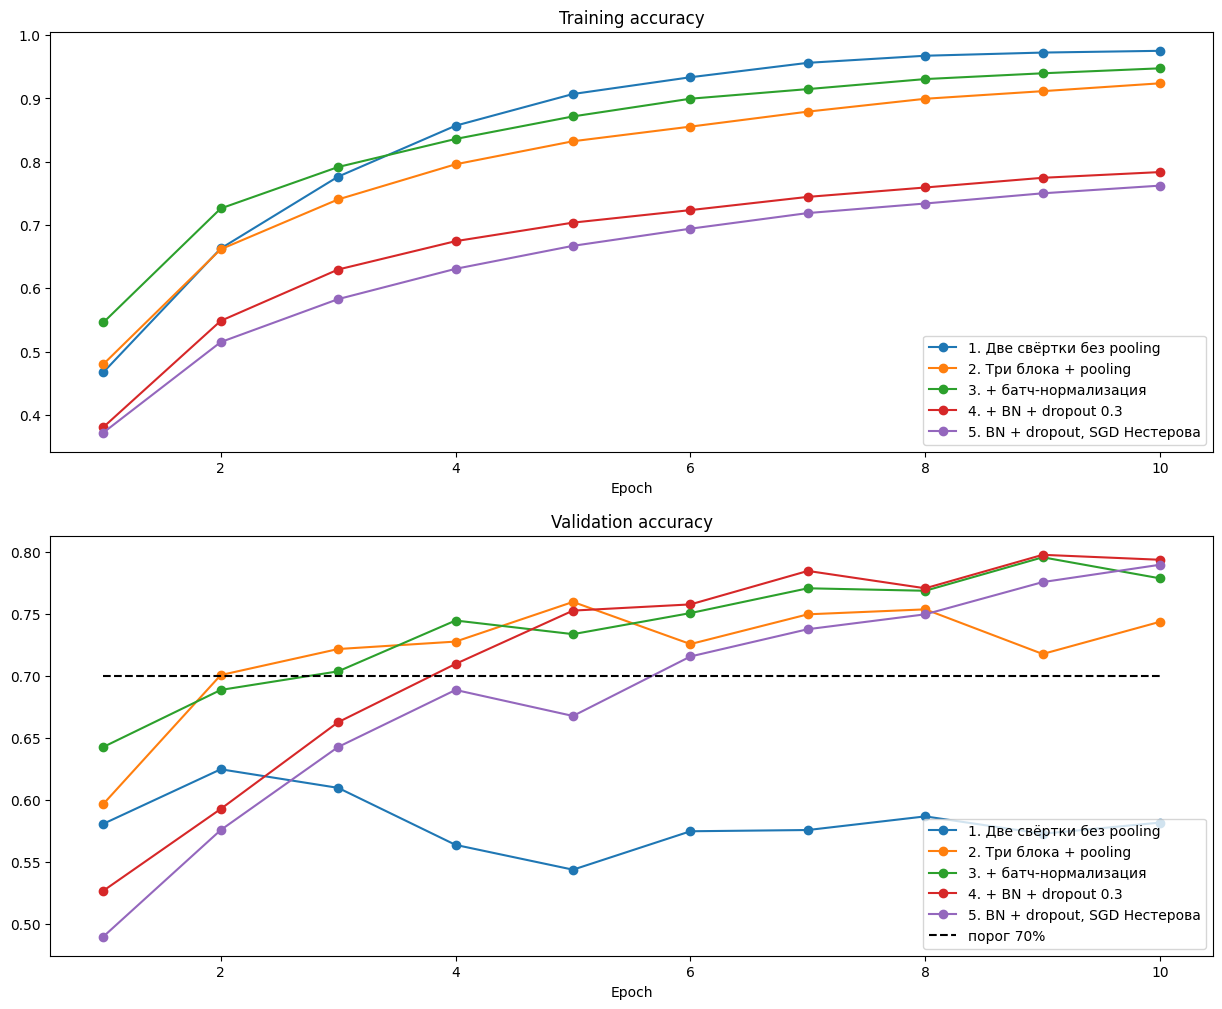

In [19]:
# Эксперименты с архитектурой и обучением свёрточной сети: каждый вариант обучается 10 эпох
EXP_EPOCHS = 10


# Свёрточная сеть из блоков «свёртка 3x3 - свёртка 3x3 - pooling»
# filters — число фильтров в каждом блоке, use_pool — уменьшать ли картинку вдвое после блока,
# use_bn — батч-нормализация после каждой свёртки, dropout_rate — доля выключаемых нейронов (0 — без dropout),
# dense_size — размер скрытого полносвязного слоя
def build_cnn(filters=(32, 64, 128), use_pool=True, use_bn=False, dropout_rate=0.0, dense_size=256):
    initializer = tf.keras.initializers.HeNormal()
    inputs = tf.keras.Input(shape=(32, 32, 3))
    x = inputs
    for f in filters:
        for _ in range(2):
            x = tf.keras.layers.Conv2D(f, 3, padding='same', use_bias=not use_bn,
                                       kernel_initializer=initializer)(x)
            if use_bn:
                x = tf.keras.layers.BatchNormalization()(x)
            x = tf.keras.layers.ReLU()(x)
        if use_pool:
            x = tf.keras.layers.MaxPooling2D(2)(x)
        if dropout_rate > 0:
            x = tf.keras.layers.Dropout(dropout_rate)(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(dense_size, activation='relu', kernel_initializer=initializer)(x)
    if dropout_rate > 0:
        x = tf.keras.layers.Dropout(dropout_rate)(x)
    outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs)


# Варианты: (название, параметры сети, функция создания оптимизатора)
experiments = [
    ('1. Две свёртки без pooling', dict(filters=(32,), use_pool=False),
     lambda: tf.keras.optimizers.Adam(1e-3)),
    ('2. Три блока + pooling', dict(),
     lambda: tf.keras.optimizers.Adam(1e-3)),
    ('3. + батч-нормализация', dict(use_bn=True),
     lambda: tf.keras.optimizers.Adam(1e-3)),
    ('4. + BN + dropout 0.3', dict(use_bn=True, dropout_rate=0.3),
     lambda: tf.keras.optimizers.Adam(1e-3)),
    ('5. BN + dropout, SGD Нестерова', dict(use_bn=True, dropout_rate=0.3),
     lambda: tf.keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True)),
]

histories = {}
for name, net_params, make_optimizer in experiments:
    print('Обучение:', name)
    tf.keras.utils.set_random_seed(231)
    with tf.device(device):
        net = build_cnn(**net_params)
        net.compile(optimizer=make_optimizer(),
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
        h = net.fit(X_train, y_train, batch_size=64, epochs=EXP_EPOCHS,
                    validation_data=(X_val, y_val), verbose=0)
    histories[name] = h.history
    print('  точность: обучение %.3f, валидация %.3f (лучшая %.3f)' % (
        h.history['accuracy'][-1], h.history['val_accuracy'][-1], max(h.history['val_accuracy'])))

# Итоговая таблица
print()
print('%-34s %10s %10s %12s' % ('Вариант', 'train_acc', 'val_acc', 'best_val'))
for name, hist in histories.items():
    print('%-34s %10.3f %10.3f %12.3f' % (name, hist['accuracy'][-1], hist['val_accuracy'][-1],
                                          max(hist['val_accuracy'])))

# Графики точности на обучении и на валидации по эпохам
epochs_axis = range(1, EXP_EPOCHS + 1)
plt.subplot(2, 1, 1)
for name, hist in histories.items():
    plt.plot(epochs_axis, hist['accuracy'], '-o', label=name)
plt.title('Training accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')

plt.subplot(2, 1, 2)
for name, hist in histories.items():
    plt.plot(epochs_axis, hist['val_accuracy'], '-o', label=name)
plt.plot(epochs_axis, [0.7] * EXP_EPOCHS, 'k--', label='порог 70%')
plt.title('Validation accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

In [20]:
class CustomConvNet(tf.keras.Model):
    def __init__(self):
        super(CustomConvNet, self).__init__()
        ############################################################################
        # TODO: Construct a model that performs well on CIFAR-10                   #
        ############################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        # Свёрточная часть: три блока «свёртка - BN - ReLU - свёртка - BN - ReLU - pooling - dropout»
        initializer = tf.keras.initializers.HeNormal()
        self.feature_layers = []
        for filters in (32, 64, 128):
            for _ in range(2):
                self.feature_layers.append(tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False,
                                                                  kernel_initializer=initializer))
                self.feature_layers.append(tf.keras.layers.BatchNormalization())
                self.feature_layers.append(tf.keras.layers.ReLU())
            self.feature_layers.append(tf.keras.layers.MaxPooling2D(2))
            self.feature_layers.append(tf.keras.layers.Dropout(0.3))

        # Классификатор: вытягивание в вектор, скрытый слой и выход с вероятностями классов
        self.flatten = tf.keras.layers.Flatten()
        self.fc = tf.keras.layers.Dense(256, activation='relu', kernel_initializer=initializer)
        self.fc_dropout = tf.keras.layers.Dropout(0.3)
        self.classifier = tf.keras.layers.Dense(10, activation='softmax')

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ############################################################################
        #                            END OF YOUR CODE                              #
        ############################################################################

    def call(self, input_tensor, training=False):
        ############################################################################
        # TODO: Construct a model that performs well on CIFAR-10                   #
        ############################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        x = input_tensor
        for layer in self.feature_layers:
            # Батч-нормализации и dropout нужно знать, идёт обучение или проверка
            if isinstance(layer, (tf.keras.layers.BatchNormalization, tf.keras.layers.Dropout)):
                x = layer(x, training=training)
            else:
                x = layer(x)
        x = self.flatten(x)
        x = self.fc(x)
        x = self.fc_dropout(x, training=training)
        x = self.classifier(x)

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ############################################################################
        #                            END OF YOUR CODE                              #
        ############################################################################
        return x


print_every = 700
num_epochs = 10

model = CustomConvNet()

def model_init_fn():
    return CustomConvNet()

def optimizer_init_fn():
    learning_rate = 1e-3
    return tf.keras.optimizers.Adam(learning_rate)

train_part34(model_init_fn, optimizer_init_fn, num_epochs=num_epochs, is_training=True)

Iteration 0, Epoch 1, Loss: 3.762829303741455, Accuracy: 4.6875, Val Loss: 5.486148834228516, Val Accuracy: 9.700000762939453
Iteration 700, Epoch 1, Loss: 1.6768344640731812, Accuracy: 38.4450798034668, Val Loss: 1.4428726434707642, Val Accuracy: 46.5
Iteration 1400, Epoch 2, Loss: 1.25233793258667, Accuracy: 54.835140228271484, Val Loss: 1.0504720211029053, Val Accuracy: 63.400001525878906
Iteration 2100, Epoch 3, Loss: 1.0655268430709839, Accuracy: 62.20068359375, Val Loss: 0.9506114721298218, Val Accuracy: 67.19999694824219
Iteration 2800, Epoch 4, Loss: 0.9445729851722717, Accuracy: 66.52584838867188, Val Loss: 0.8269380331039429, Val Accuracy: 72.39999389648438
Iteration 3500, Epoch 5, Loss: 0.8620915412902832, Accuracy: 69.77974700927734, Val Loss: 0.8047733902931213, Val Accuracy: 72.0999984741211
Iteration 4200, Epoch 6, Loss: 0.7920096516609192, Accuracy: 72.14032745361328, Val Loss: 0.6548330187797546, Val Accuracy: 76.5
Iteration 4900, Epoch 7, Loss: 0.7463141083717346, Acc

Опишите все эксперименты, результаты. Сделайте выводы.

**Описание экспериментов.** Все варианты обучались 10 эпох на 49 000 картинках CIFAR-10 с батчем 64; точность смотрелась на 1000 валидационных картинках. Таблица и графики — в ячейке с экспериментами выше.

1. **Базовая сеть: две свёртки без pooling** (как трёхслойная сеть из первой части, но с Adam). Картинка не уменьшается, поэтому у полносвязного слоя очень много весов. Сеть быстро запоминает обучающие картинки: точность на обучении 0.975, а на валидации — 0.582 (лучшая 0.625), заметно ниже 70%. После 2-й эпохи точность на валидации даже падает — сеть переобучается.
2. **Три блока «свёртка-свёртка-pooling» (32 → 64 → 128 фильтров).** Pooling уменьшает картинку и число весов, а несколько блоков позволяют сети собирать сложные признаки из простых. Точность на валидации выросла до 0.744 (лучшая 0.760), но разрыв с обучением (0.924) большой — переобучение остаётся.
3. **+ батч-нормализация после каждой свёртки.** Обучение идёт быстрее: уже после 1-й эпохи 0.643 на валидации против 0.597 без нормализации. Итог на валидации — 0.779 (лучшая 0.796).
4. **+ dropout 0.3 после каждого блока и перед выходом.** Точность на обучении растёт медленнее (0.784), зато разрыв с валидацией исчезает, и итоговая точность на валидации — лучшая среди вариантов: 0.794 (лучшая 0.798). Этот вариант взят за итоговую модель `CustomConvNet`.
5. **Та же сеть, но SGD с моментом Нестерова вместо Adam.** В первые эпохи заметно отстаёт от Adam (после 5-й эпохи 0.668 против 0.753), но к 10-й эпохе почти догоняет: 0.790 против 0.794.

**Итоговая модель** `CustomConvNet` (три блока, батч-нормализация, dropout 0.3, Adam), обученная циклом `train_part34`, дала **78.7%** на валидации за 10 эпох.

**Выводы.**
- Главный прирост дала архитектура: несколько свёрточных блоков с pooling вместо двух свёрток без уменьшения картинки (с 0.58 до 0.74).
- Батч-нормализация ускоряет обучение и добавляет ещё несколько процентов точности.
- Dropout борется с переобучением: точность на обучении и на валидации почти сравнялись, а на валидации она стала лучшей.
- Adam сходится быстрее SGD с моментом Нестерова, хотя к 10-й эпохе разница почти исчезает.
- Итоговая модель превышает требуемые 70% на валидации за 10 эпох.